<a href="https://colab.research.google.com/github/Mhmd-Seyed/ecommerce-behavior-analytics/blob/main/Copy_of_05_funnel_and_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pyspark matplotlib seaborn

import os
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Spark oturumunu başlat
spark = SparkSession.builder \
    .appName("Student5_Funnel_And_Benchmark") \
    .config("spark.driver.memory", "8g") \
    .getOrCreate()

base_dir = "/content/drive/MyDrive/ecommerce_project"
charts_dir = f"{base_dir}/charts"
os.makedirs(charts_dir, exist_ok=True)

# Ekip arkadaşlarının Drive'a kaydettiği tüm dosyaları kontrol et
print("Klasördeki mevcut dosyalar:")
for f in sorted(os.listdir(base_dir)):
    print(" ->", f)

Klasördeki mevcut dosyalar:
 -> benchmark_results.csv
 -> category_analysis.csv
 -> charts
 -> conversion_metrics.csv
 -> customer_segments.csv
 -> events_clean.parquet
 -> feature_importance.csv
 -> hourly_trends.csv
 -> ml_model_metrics.csv
 -> rfm_clusters.csv
 -> sessions_summary.parquet
 -> top_products.csv


Kullanılabilir toplam satır sayısı: 1,141,025
Boyut: 100,000 satır | PySpark: 1.422 sn | Pandas: 0.287 sn | Hız Farkı: 0.2x
Boyut: 1,000,000 satır | PySpark: 2.391 sn | Pandas: 1.668 sn | Hız Farkı: 0.7x
5,000,000 satır mevcut veriden büyük olduğu için atlandı.


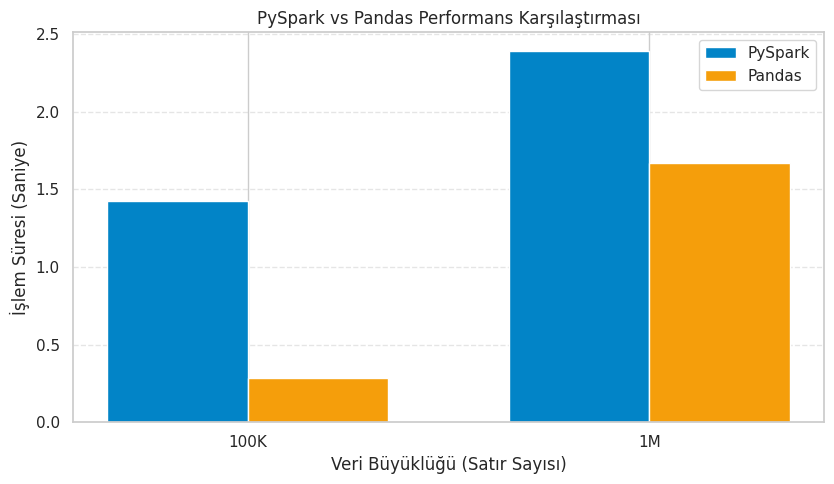

In [ ]:
# 1. Öğrenci 1'in temiz verisini oku ve ana kategoriyi oluştur
data_path = f"{base_dir}/events_clean.parquet"
full_df = spark.read.parquet(data_path).withColumn(
    "main_category", F.split(F.col("category_code"), "\\.").getItem(0)
)

total_available = full_df.count()
print(f"Kullanılabilir toplam satır sayısı: {total_available:,}")

# Test edilecek veri büyüklükleri (100 Bin, 1 Milyon, 5 Milyon satır)
sample_sizes = [100_000, 1_000_000, 5_000_000]
benchmark_results = []

for size in sample_sizes:
    if size > total_available:
        print(f"{size:,} satır mevcut veriden büyük olduğu için atlandı.")
        continue

    # Belirtilen boyutta alt küme oluştur ve yerel geçici Parquet olarak kaydet
    sub_path = f"/content/bench_{size}.parquet"
    full_df.limit(size).write.mode("overwrite").parquet(sub_path)

    # --- A) PYSPARK SÜRE ÖLÇÜMÜ (Okuma + Filtreleme + Gruplama + Eylem) ---
    t0 = time.time()
    sp_df = spark.read.parquet(sub_path)
    sp_agg = sp_df.filter(F.col("price") > 10) \
        .groupBy("main_category", "event_type") \
        .agg(F.count("*").alias("cnt"), F.sum("price").alias("total_price")) \
        .toPandas()
    spark_time = round(time.time() - t0, 3)

    # --- B) PANDAS SÜRE ÖLÇÜMÜ (Aynı işlem geleneksel Pandas ile) ---
    t1 = time.time()
    pd_df = pd.read_parquet(sub_path)
    pd_agg = pd_df[pd_df["price"] > 10] \
        .groupby(["main_category", "event_type"], as_index=False) \
        .agg(cnt=("price", "count"), total_price=("price", "sum"))
    pandas_time = round(time.time() - t1, 3)

    speedup = round(pandas_time / max(spark_time, 0.001), 2)
    benchmark_results.append({
        "row_count": size,
        "pyspark_sec": spark_time,
        "pandas_sec": pandas_time,
        "spark_speedup_x": speedup
    })
    print(f"Boyut: {size:,} satır | PySpark: {spark_time} sn | Pandas: {pandas_time} sn | Hız Farkı: {speedup}x")

# Sonuç tablosunu kaydet ve karşılaştırma grafiğini çiz
bench_df = pd.DataFrame(benchmark_results)
bench_df.to_csv(f"{base_dir}/benchmark_results.csv", index=False)

plt.figure(figsize=(8.5, 5))
x_labels = [f"{int(r/1000):,}K" if r < 1_000_000 else f"{int(r/1_000_000)}M" for r in bench_df["row_count"]]
x = range(len(x_labels))
width = 0.35

plt.bar([i - width/2 for i in x], bench_df["pyspark_sec"], width=width, label="PySpark", color="#0284c7")
plt.bar([i + width/2 for i in x], bench_df["pandas_sec"], width=width, label="Pandas", color="#f59e0b")

plt.xticks(list(x), x_labels)
plt.xlabel("Veri Büyüklüğü (Satır Sayısı)")
plt.ylabel("İşlem Süresi (Saniye)")
plt.title("PySpark vs Pandas Performans Karşılaştırması")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(f"{charts_dir}/01_spark_vs_pandas_benchmark.png", dpi=300)
plt.show()

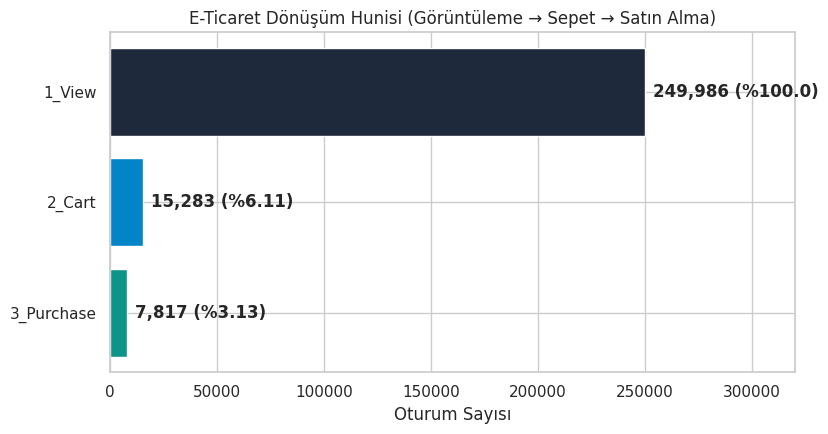

/tmp/ipykernel_671/1497154883.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=c_df, x=rev_col, y=cat_col, palette="Blues_r")


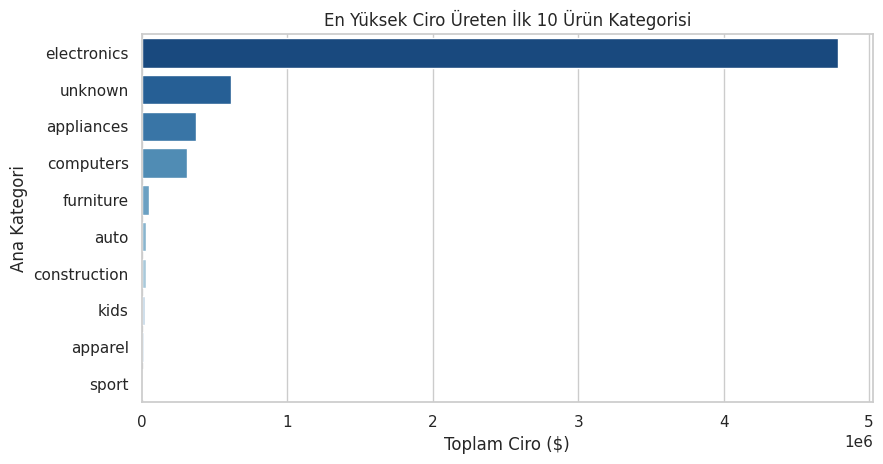

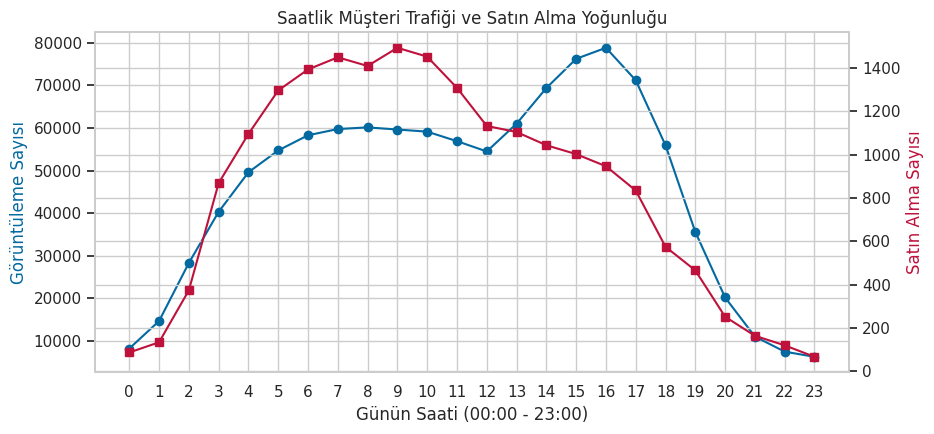

/tmp/ipykernel_671/1497154883.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=s_df, x=s_df.columns[0], y=s_df.columns[1], palette="viridis")


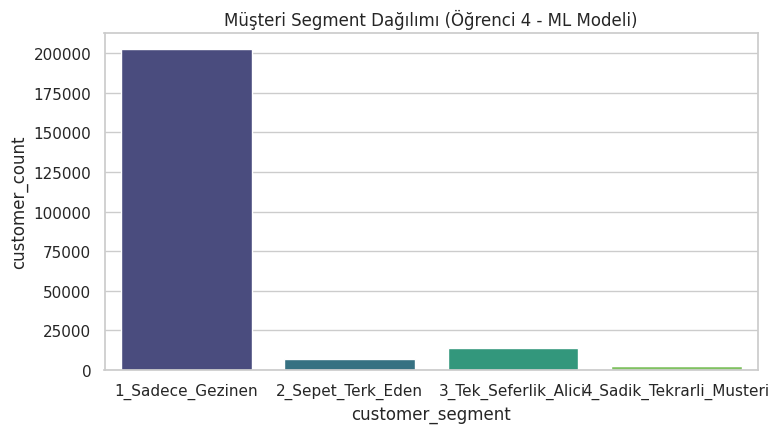

Tüm grafikler başarıyla oluşturuldu ve şu klasöre kaydedildi: /content/drive/MyDrive/ecommerce_project/charts


In [ ]:
# 1. SATIŞ HUNİSİ (FUNNEL) GRAFİĞİ (Öğrenci 2'nin çıktısından)
funnel_file = f"{base_dir}/conversion_metrics.csv"
if os.path.exists(funnel_file):
    f_df = pd.read_csv(funnel_file)
    # Yüzde sütunu adını otomatik yakala (pct_of_initial_view veya percentage_from_view)
    pct_col = [c for c in f_df.columns if "pct" in c or "percent" in c][0]

    plt.figure(figsize=(8.5, 4.5))
    bars = plt.barh(f_df["stage"][::-1], f_df["sessions_count"][::-1], color=["#0d9488", "#0284c7", "#1e293b"])
    for bar, pct in zip(bars, f_df[pct_col][::-1]):
        plt.text(
            bar.get_width() + (f_df["sessions_count"].max() * 0.015),
            bar.get_y() + bar.get_height() / 2,
            f"{int(bar.get_width()):,} (%{pct})",
            va="center", fontweight="bold"
        )
    plt.xlim(0, f_df["sessions_count"].max() * 1.28)
    plt.xlabel("Oturum Sayısı")
    plt.title("E-Ticaret Dönüşüm Hunisi (Görüntüleme → Sepet → Satın Alma)")
    plt.tight_layout()
    plt.savefig(f"{charts_dir}/02_conversion_funnel.png", dpi=300)
    plt.show()
else:
    print("Uyarı: conversion_metrics.csv bulunamadı.")

# 2. KATEGORİ BAZLI CİRO GRAFİĞİ (Öğrenci 3'ün çıktısından)
cat_file = f"{base_dir}/category_analysis.csv"
if os.path.exists(cat_file):
    c_df = pd.read_csv(cat_file).head(10)
    cat_col = c_df.columns[0]
    rev_col = [c for c in c_df.columns if "rev" in c or "ciro" in c or "sum" in c or "sales" in c][-1]

    plt.figure(figsize=(9, 4.8))
    sns.barplot(data=c_df, x=rev_col, y=cat_col, palette="Blues_r")
    plt.xlabel("Toplam Ciro ($)")
    plt.ylabel("Ana Kategori")
    plt.title("En Yüksek Ciro Üreten İlk 10 Ürün Kategorisi")
    plt.tight_layout()
    plt.savefig(f"{charts_dir}/03_category_revenue.png", dpi=300)
    plt.show()
else:
    print("Uyarı: category_analysis.csv bulunamadı.")

# 3. SAATLİK ZAMAN ANALİZİ GRAFİĞİ (Öğrenci 3'ün çıktısından)
hour_file = f"{base_dir}/hourly_trends.csv"
if os.path.exists(hour_file):
    h_df = pd.read_csv(hour_file)
    hour_col = h_df.columns[0]
    view_col = [c for c in h_df.columns if "view" in c][0]
    purch_col = [c for c in h_df.columns if "purch" in c][0]

    fig, ax1 = plt.subplots(figsize=(9.5, 4.5))
    ax1.plot(h_df[hour_col], h_df[view_col], marker="o", color="#0369a1", label="Görüntüleme Sayısı")
    ax1.set_xlabel("Günün Saati (00:00 - 23:00)")
    ax1.set_ylabel("Görüntüleme Sayısı", color="#0369a1")
    ax1.set_xticks(range(0, 24))

    ax2 = ax1.twinx()
    ax2.plot(h_df[hour_col], h_df[purch_col], marker="s", color="#be123c", label="Satın Alma Sayısı")
    ax2.set_ylabel("Satın Alma Sayısı", color="#be123c")

    plt.title("Saatlik Müşteri Trafiği ve Satın Alma Yoğunluğu")
    fig.tight_layout()
    plt.savefig(f"{charts_dir}/04_hourly_activity.png", dpi=300)
    plt.show()
else:
    print("Uyarı: hourly_trends.csv bulunamadı.")

# 4. MÜŞTERİ SEGMENTASYONU GRAFİĞİ (Öğrenci 4 CSV kaydettiyse otomatik çizer)
for seg_name in ["rfm_segments.csv", "customer_segments.csv", "segment_summary.csv"]:
    seg_file = f"{base_dir}/{seg_name}"
    if os.path.exists(seg_file):
        s_df = pd.read_csv(seg_file)
        plt.figure(figsize=(8, 4.5))
        sns.barplot(data=s_df, x=s_df.columns[0], y=s_df.columns[1], palette="viridis")
        plt.title("Müşteri Segment Dağılımı (Öğrenci 4 - ML Modeli)")
        plt.tight_layout()
        plt.savefig(f"{charts_dir}/05_customer_segments.png", dpi=300)
        plt.show()
        break

print("Tüm grafikler başarıyla oluşturuldu ve şu klasöre kaydedildi:", charts_dir)

/tmp/ipykernel_671/2231755551.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x=imp_col, y=feat_col, palette="crest")


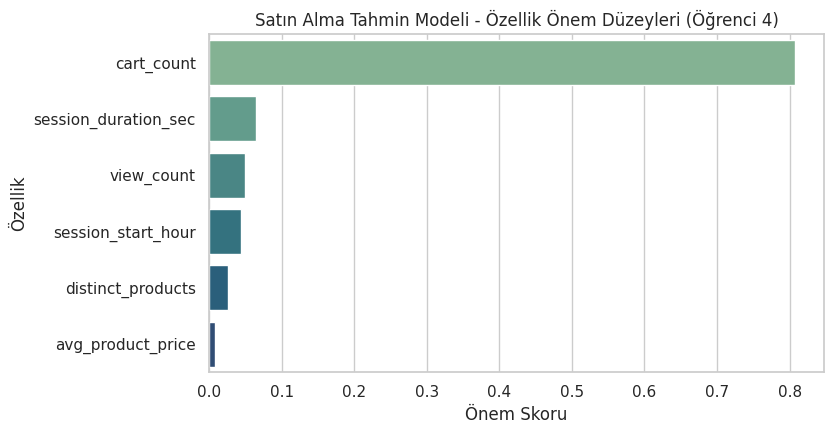

/tmp/ipykernel_671/2231755551.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rfm_df, x=cluster_col, y=y_col, palette="magma")


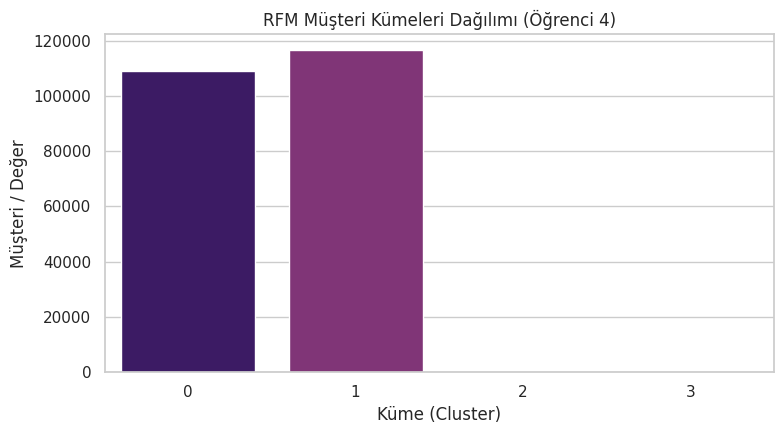

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

base_dir = "/content/drive/MyDrive/ecommerce_project"
charts_dir = f"{base_dir}/charts"

# 1. Özellik Önemi Grafiği (Öğrenci 4 - feature_importance.csv)
fi_file = f"{base_dir}/feature_importance.csv"
if os.path.exists(fi_file):
    fi_df = pd.read_csv(fi_file)
    feat_col, imp_col = fi_df.columns[0], fi_df.columns[1]
    fi_df = fi_df.sort_values(by=imp_col, ascending=False).head(10)

    plt.figure(figsize=(8.5, 4.5))
    sns.barplot(data=fi_df, x=imp_col, y=feat_col, palette="crest")
    plt.title("Satın Alma Tahmin Modeli - Özellik Önem Düzeyleri (Öğrenci 4)")
    plt.xlabel("Önem Skoru")
    plt.ylabel("Özellik")
    plt.tight_layout()
    plt.savefig(f"{charts_dir}/06_ml_feature_importance.png", dpi=300)
    plt.show()

# 2. RFM Küme Dağılımı Grafiği (Öğrenci 4 - rfm_clusters.csv)
rfm_file = f"{base_dir}/rfm_clusters.csv"
if os.path.exists(rfm_file):
    rfm_df = pd.read_csv(rfm_file)
    cluster_col = rfm_df.columns[0]
    count_col = [c for c in rfm_df.columns if "count" in c or "size" in c or "musteri" in c or "customer" in c]
    y_col = count_col[0] if count_col else rfm_df.columns[1]

    plt.figure(figsize=(8, 4.5))
    sns.barplot(data=rfm_df, x=cluster_col, y=y_col, palette="magma")
    plt.title("RFM Müşteri Kümeleri Dağılımı (Öğrenci 4)")
    plt.xlabel("Küme (Cluster)")
    plt.ylabel("Müşteri / Değer")
    plt.tight_layout()
    plt.savefig(f"{charts_dir}/07_rfm_clusters.png", dpi=300)
    plt.show()